In [1]:
import os
import sys
import warnings

sys.path.append("/path/to/GeneSPOT")
warnings.filterwarnings("ignore")
os.environ['R_HOME'] = '/path/to/R'

In [2]:
from pathlib import Path
import seaborn as sns
import numpy as np
import pandas as pd
import scanpy as sc
import mudata as mu
from tqdm import tqdm
from scipy.stats import gaussian_kde
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics.pairwise import cosine_similarity
from statannotations.Annotator import Annotator
from adjustText import adjust_text
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors

# plt.rcParams['font.family'] = 'sans-serif'
# plt.rcParams['font.sans-serif'] = ['Arial']
matplotlib.rcParams['pdf.fonttype'] = 42

In [3]:
%load_ext autoreload
%autoreload 2

from genespot.utils import seed_everything
from genespot.genespot import query_from_multidatasets
from genespot.visualization import create_cmap

random_state = 42
seed_everything(random_state)

In [4]:
from palettable.colorbrewer.diverging import Spectral_11_r, RdBu_3_r

In [5]:
DATA_DIR = Path('/path/to/GeneSPOT/data/stereo_seq_embryo')
RES_DIR = Path('/path/to/GeneSPOT/reproduce/fig4/res')
OUTPUTS_DIR = Path('/path/to/GeneSPOT/reproduce/fig4/outputs')

os.makedirs(RES_DIR, exist_ok=True)
os.makedirs(OUTPUTS_DIR, exist_ok=True)

In [6]:
times = ['E9.5', 'E10.5', 'E11.5', 'E12.5', 'E13.5', 'E14.5', 'E15.5', 'E16.5']
adata = sc.read_h5ad(DATA_DIR / 'stereo_seq_embryo_cleaned.h5ad')
adata = adata[adata.obs['time'].isin(times)]

## Data Access
# Intermediate results generated by GeneSPOT (such as `gdata` objects) can be accessed from our [Google Drive repository](https://drive.google.com/drive/folders/1tnBl9eoA4dg37sBTJ9SPBMAjqhwMR8aj?usp=sharing).
gene_list = pd.read_csv(DATA_DIR / 'aligned_gene_list.csv', header=None).values.reshape(-1,).tolist()
annotations = adata.obs['annotation'].cat.categories.values

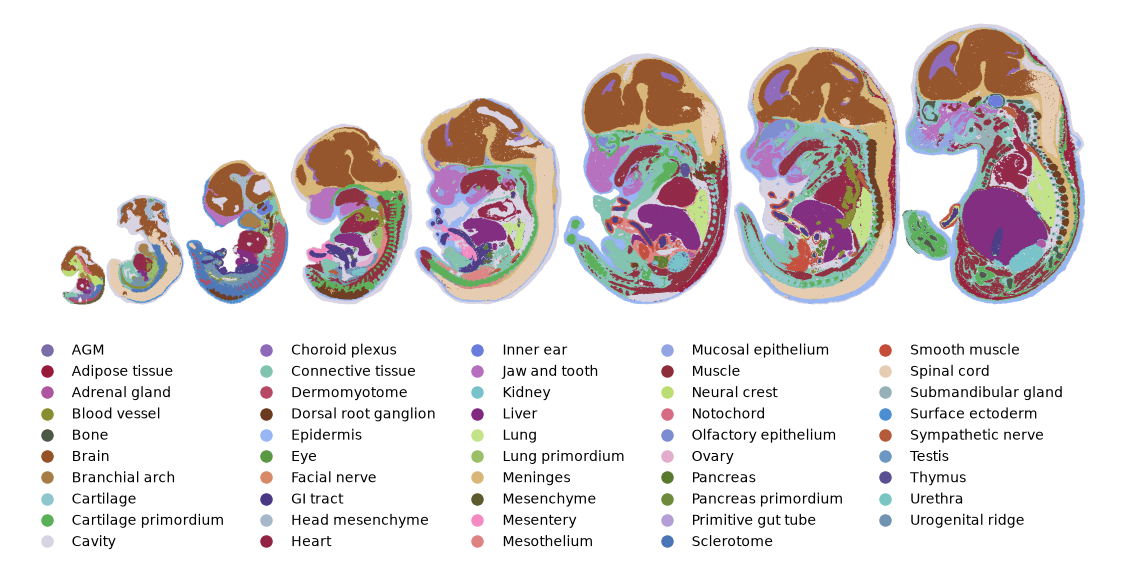

In [7]:
fig, axs = plt.subplots(1, 1, figsize=(20, 4))
annotation_palette = adata.uns['annotation_palette']
sc.pl.embedding(
    adata,
    color='annotation', basis='spatial', ax=axs, show=False, 
    palette=annotation_palette, title='',
    frameon=False, size=2, legend_loc=None)
axs.set_aspect(1)
axs.invert_yaxis()

legend_elements = [
    Line2D(
        [0], [0], 
        marker='o', color='w', 
        label=label, markerfacecolor=color, 
        markersize=10) for label, color in annotation_palette.items()
]

fig.legend(
    handles=legend_elements,
    loc='lower center',
    ncol=5,
    frameon=False,
    bbox_to_anchor=(0.5, -0.5)
)

plt.savefig(OUTPUTS_DIR / 'fig4a.pdf', format='pdf', dpi=300, bbox_inches='tight')
plt.show()

In [8]:
gdata_dict = dict()
gene2landmark_dict = dict()
gene2gene_dict = dict()

for i, time in enumerate(times):
    ## Data Access
    # Intermediate results generated by GeneSPOT (such as `gdata` objects) can be accessed from our [Google Drive repository](https://drive.google.com/drive/folders/1tnBl9eoA4dg37sBTJ9SPBMAjqhwMR8aj?usp=sharing).
    gdata = sc.read_h5ad(DATA_DIR / f'{time}_gdata_aggbymean_landmark.h5ad')
    gdata_dict[time] = gdata
    landmarks = gdata_dict[time][gdata_dict[time].obs['feature_types'] == 'SpatialLandmark'].obs_names.values
    gene2landmark = cosine_similarity(
        gdata_dict[time][gene_list].obsm['feature_embedding'],
        gdata_dict[time][landmarks].obsm['feature_embedding'],
    )
    gene2landmark = pd.DataFrame(gene2landmark, index=gene_list, columns=landmarks)
    gene2landmark = gene2landmark.reindex(columns=[f'SpatialLandmark_{ann}' for ann in annotations], fill_value=0)
    gene2landmark_dict[time] = gene2landmark

    gene2gene = cosine_similarity(
        gdata_dict[time][gene_list].obsm['feature_embedding']
    )
    gene2gene = pd.DataFrame(gene2gene, index=gene_list, columns=gene_list)
    gene2gene_dict[time] = gene2gene

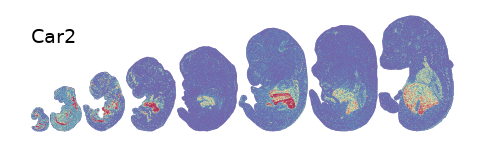

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))
sc.pl.embedding(adata, color='Car2', basis='spatial', ax=ax, show=False, cmap=Spectral_11_r.mpl_colormap, colorbar_loc=None, vmax='p99')
ax.set_aspect(1)
ax.invert_yaxis()
ax.set_title('')
ax.set_ylabel('')
ax.set_xlabel('')
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.text(
    adata.obsm['spatial'][:, 0].min(), 120,
    'Car2',
    fontsize=14, linespacing=1.5
)

plt.savefig(OUTPUTS_DIR / 'fig4c.eps', format='eps', dpi=300, bbox_inches='tight')
plt.show()

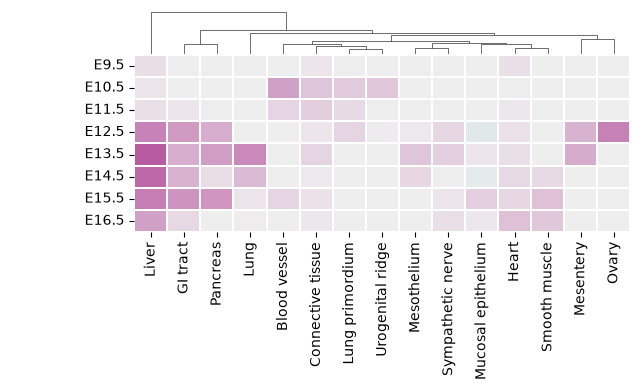

In [10]:
car22landmark_over_time = []
for time in times:
    gdata = gdata_dict[time]
    g2l = gene2landmark_dict[time].loc[['Car2'], [f'SpatialLandmark_{ann}' for ann in annotations]]
    car22landmark_over_time.append(g2l)

car22landmark_over_time = pd.concat(car22landmark_over_time, axis=0).T
car22landmark_over_time.columns = times
car22landmark_over_time = car22landmark_over_time.loc[[f'SpatialLandmark_{ann}' for ann in annotations]]
car22landmark_over_time = car22landmark_over_time.loc[car22landmark_over_time.max(1) >= 0.2]

cg = sns.clustermap(
    car22landmark_over_time.T,
    col_cluster=True,
    row_cluster=False,
    xticklabels=list(map(lambda x: x.split('_')[1], car22landmark_over_time.index)),
    yticklabels=times,
    cmap=create_cmap(['#318e93', '#efefef' ,'#b657a0'], [0, 0.5, 1]),
    vmin=-1, vmax=1,
    cbar_pos=None,
    annot=False, fmt=".2f", linewidths=0.1, square=True,
    figsize=(7, 4)
)
plt.setp(cg.ax_heatmap.xaxis.get_majorticklabels(), rotation=90)
cg.ax_heatmap.tick_params(
    left=True, bottom=True, right=False, top=False,
    labelleft=True, labelbottom=True, labelright=False, labeltop=False)

plt.savefig(OUTPUTS_DIR / 'fig5d2.eps', format='eps', dpi=300, bbox_inches='tight')
plt.show()

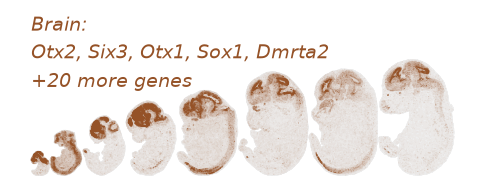

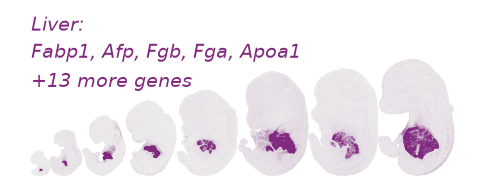

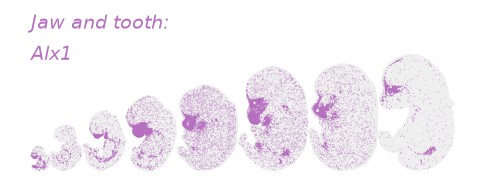

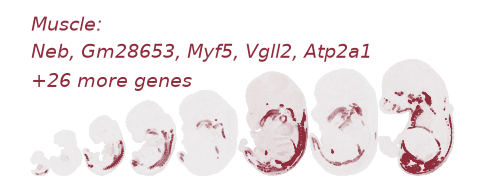

In [11]:
metric_threshold = 0.7

for j, query_tissue in enumerate(['Brain', 'Liver', 'Jaw and tooth', 'Muscle']):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3))
    
    genes = query_from_multidatasets(
        gdata_list=gdata_dict.values(),
        query=f'SpatialLandmark_{query_tissue}',
        ftype='Gene', ftype_key='feature_types', query_mode='embedding', metric='cosine_similarity', 
        n=None, smaller_is_better=False, metric_threshold=metric_threshold
    )
    gene_list = genes.sort_values(by=(f'SpatialLandmark_{query_tissue}', 'mean_metric'), ascending=False).index.values.tolist()

    adata.obs[f'GC_{query_tissue}'] = adata[:, gene_list].X.mean(1)
    sc.pl.embedding(adata, color=f'GC_{query_tissue}', basis='spatial', ax=ax, show=False, colorbar_loc=None, 
                    cmap=create_cmap(['#efefef', adata.uns['annotation_palette'][query_tissue]], [0, 1]),
                    vmax='p99',
                    size=2)
    ax.set_aspect(1)
    ax.set_title('')
    ax.invert_yaxis()
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.set_label_position("right")

    pattern_info = f'{query_tissue}: \n' + ', '.join(gene_list[:5])
    if len(gene_list) > 5:
        pattern_info += f'\n+{len(gene_list)-5} more genes'
    else:
        pattern_info += '\n'
    
    ax.text(
        adata.obsm['spatial'][:, 0].min(), 120,
        pattern_info,
        fontdict={'style':'italic'},
        c=adata.uns['annotation_palette'][query_tissue],
        fontsize=14, linespacing=1.5
    )
    plt.savefig(OUTPUTS_DIR / 'fig4d_{query_tissue}.eps', format='eps', dpi=300, bbox_inches='tight')
    plt.show()

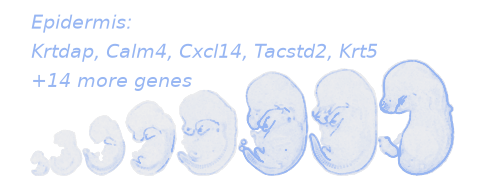

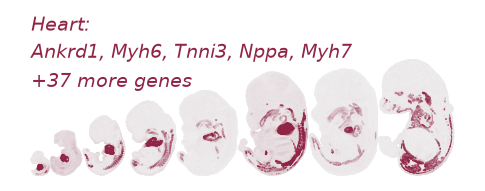

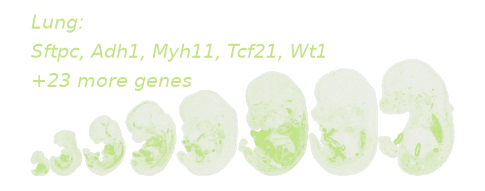

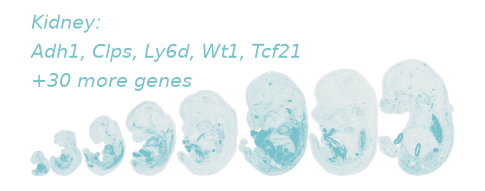

In [12]:
metric_threshold = 0.5

for j, query_tissue in enumerate(['Epidermis', 'Heart', 'Lung', 'Kidney']):
    fig, ax = plt.subplots(1, 1, figsize=(6, 3))
    
    genes = query_from_multidatasets(
        gdata_list=gdata_dict.values(),
        query=f'SpatialLandmark_{query_tissue}',
        ftype='Gene', ftype_key='feature_types', query_mode='embedding', metric='cosine_similarity', 
        n=None, smaller_is_better=False, metric_threshold=metric_threshold
    )
    gene_list = genes.sort_values(by=(f'SpatialLandmark_{query_tissue}', 'mean_metric'), ascending=False).index.values.tolist()

    adata.obs[f'GC_{query_tissue}'] = adata[:, gene_list].X.mean(1)
    sc.pl.embedding(adata, color=f'GC_{query_tissue}', basis='spatial', ax=ax, show=False, colorbar_loc=None, 
                    layer='raw',
                    cmap=create_cmap(['#efefef', adata.uns['annotation_palette'][query_tissue]], [0, 1]),
                    vmax='p99',
                    size=2)
    ax.set_aspect(1)
    ax.set_title('')
    ax.invert_yaxis()
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.spines['top'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.yaxis.set_label_position("right")
    pattern_info = f'{query_tissue}: \n' + ', '.join(gene_list[:5])
    if len(gene_list) > 5:
        pattern_info += f'\n+{len(gene_list)-5} more genes'
    else:
        pattern_info += '\n'
    
    ax.text(
        adata.obsm['spatial'][:, 0].min(), 120,
        pattern_info,
        c=adata.uns['annotation_palette'][query_tissue],
        fontdict={'style':'italic'},
        fontsize=14, linespacing=1.5
    )
    plt.savefig(OUTPUTS_DIR / 'fig4d_{query_tissue}.eps', format='eps', dpi=300, bbox_inches='tight')
    plt.show()


===== Brain : boxplot stats (median, Q1, Q3, IQR, whiskers, n) =====
  E9.5: median=0.877, Q1=0.727, Q3=0.933, IQR=0.206, whisker=[0.419, 0.990], n=46
  E10.5: median=0.760, Q1=0.520, Q3=0.879, IQR=0.359, whisker=[-0.018, 0.960], n=46
  E11.5: median=0.690, Q1=0.107, Q3=0.954, IQR=0.847, whisker=[-0.038, 0.992], n=46
  E12.5: median=0.898, Q1=0.613, Q3=0.940, IQR=0.326, whisker=[0.124, 0.991], n=46
  E13.5: median=0.799, Q1=0.563, Q3=0.945, IQR=0.381, whisker=[0.024, 0.984], n=46
  E14.5: median=0.874, Q1=0.840, Q3=0.936, IQR=0.095, whisker=[0.697, 0.987], n=46
  E15.5: median=0.613, Q1=0.488, Q3=0.652, IQR=0.164, whisker=[0.241, 0.833], n=46
  E16.5: median=0.959, Q1=0.806, Q3=0.982, IQR=0.175, whisker=[0.544, 0.995], n=46

===== Liver : boxplot stats (median, Q1, Q3, IQR, whiskers, n) =====
  E9.5: median=0.339, Q1=0.085, Q3=0.992, IQR=0.908, whisker=[-0.060, 0.996], n=37
  E10.5: median=0.981, Q1=0.070, Q3=0.991, IQR=0.921, whisker=[0.042, 0.995], n=37
  E11.5: median=0.933, Q1=0.1

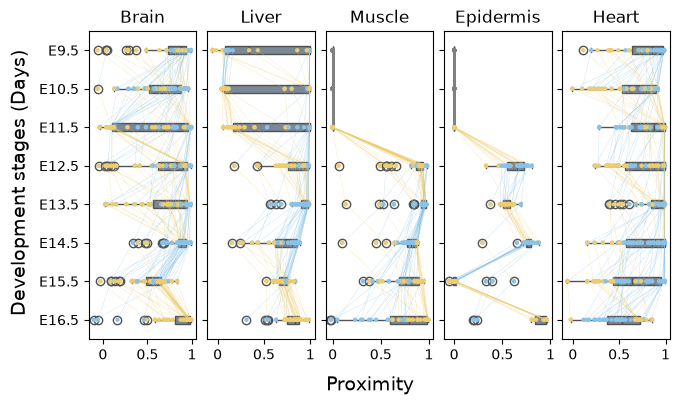

Excel export skipped: No module named 'openpyxl'
  Tissue    Gene  Time  Proxmity
0  Brain    Otx2  E9.5  0.975808
1  Brain    Six3  E9.5  0.760084
2  Brain    Otx1  E9.5  0.972960
3  Brain    Sox1  E9.5  0.967286
4  Brain  Dmrta2  E9.5  0.863233
Total points: 1472


In [13]:
import pingouin as pg
fig, axs = plt.subplots(1, 5, figsize=(5 * 1.5, 4), sharey=True)

source_data = []
for i, tissue in enumerate(['Brain', 'Liver', 'Muscle', 'Epidermis', 'Heart']):
    ax=axs[i]
    res = query_from_multidatasets(
        query=f'SpatialLandmark_{tissue}',
        ftype='Gene', ftype_key='feature_types',
        gdata_list=gdata_dict.values(),
        metric='cosine_similarity',
        metric_threshold=0.5,
        smaller_is_better=False,
    )
    apps = pd.DataFrame(np.stack(res[(f'SpatialLandmark_{tissue}', 'metrics')].values, axis=0), columns=times, index=res.index.values)
    apps_melt = pd.melt(
        apps.reset_index(),
        id_vars=['index'],
        var_name='Time'
    )
    apps_melt.columns = ['Gene', 'Time', 'Proxmity']
    apps_melt['Tissue'] = tissue
    source_data.append(apps_melt)
    
    pg.plot_paired(
        data=apps_melt, dv='Proxmity', 
        within='Time', order=times,
        subject='Gene', boxplot_in_front=False,
        boxplot=True,
        colors=['#efcc6c', 'grey', '#88c2ea'],
        orient='h',
        pointplot_kwargs={'scale': 0.05},
        ax=ax
    )
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_title(tissue)
    ax.set_xticks([0, 0.5, 1], [0, 0.5, 1])

    # --- boxplot statistics per Time level ---
    print(f"\n===== {tissue} : boxplot stats (median, Q1, Q3, IQR, whiskers, n) =====")
    for t in times:
        vals = apps_melt.loc[apps_melt['Time'] == t, 'Proxmity'].values
        q1, med, q3 = np.percentile(vals, [25, 50, 75])
        iqr = q3 - q1
        w_lo = max(vals.min(), q1 - 1.5 * iqr)
        w_hi = min(vals.max(), q3 + 1.5 * iqr)
        n = len(vals)
        print(f"  {t}: median={med:.3f}, Q1={q1:.3f}, Q3={q3:.3f}, IQR={iqr:.3f}, "
              f"whisker=[{w_lo:.3f}, {w_hi:.3f}], n={n}")

fig.supxlabel("Proximity", fontsize=14, y=-0.03)
fig.supylabel("Development stages (Days)", fontsize=14)
plt.subplots_adjust(wspace=0.1, hspace=0.4)
plt.savefig(OUTPUTS_DIR / 'fig4e.eps', format='eps', dpi=300, bbox_inches='tight')    
plt.show()

source_df = pd.concat(source_data, ignore_index=True)
source_df = source_df[['Tissue', 'Gene', 'Time', 'Proxmity']]
source_df.to_csv(OUTPUTS_DIR / 'fig4e_source_data.csv', index=False)
try:
    source_df.to_excel(OUTPUTS_DIR / 'fig4e_source_data.xlsx', index=False)
except Exception as e:
    print(f"Excel export skipped: {e}")
print(source_df.head())
print(f"Total points: {len(source_df)}")

In [14]:
import igraph as ig
import networkx as nx

def matrix_to_graph(sim_matrix, threshold=0.75):
    g = ig.Graph()
    n = sim_matrix.shape[0]
    g.add_vertices(n)
    edges = [(i, j) for i in range(n) for j in range(i+1, n) if sim_matrix[i, j] > threshold]
    weights = [sim_matrix[i, j] for i, j in edges]
    g.add_edges(edges)
    g.es["weight"] = weights
    return g

def matrix_to_graph_topk(sim_matrix, topk=3):
    n = sim_matrix.shape[0]
    g = ig.Graph()
    g.add_vertices(n)
    
    edge_set = set()
    weights = {}

    for i in range(n):
        row = sim_matrix[i].copy()
        row[i] = -np.inf
        top_k_indices = np.argsort(row)[-topk:]
        for j in top_k_indices:
            edge = tuple(sorted((i, j)))
            if edge not in edge_set:
                edge_set.add(edge)
                weights[edge] = sim_matrix[i, j]

    edge_list = list(edge_set)
    g.add_edges(edge_list)
    g.es["weight"] = [weights[edge] for edge in edge_list]

    return g

def color_by_degree(graph, cmap=RdBu_3_r.get_mpl_colormap()):
    degrees = graph.degree()
    norm = mcolors.Normalize(vmin=min(degrees), vmax=max(degrees))
    return [mcolors.to_hex(cmap(norm(d))) for d in degrees]

def color_by_scores(scores, cmap=RdBu_3_r.get_mpl_colormap()):
    norm = mcolors.Normalize(vmin=min(scores), vmax=max(scores))
    return [mcolors.to_hex(cmap(norm(d))) for d in scores]

44


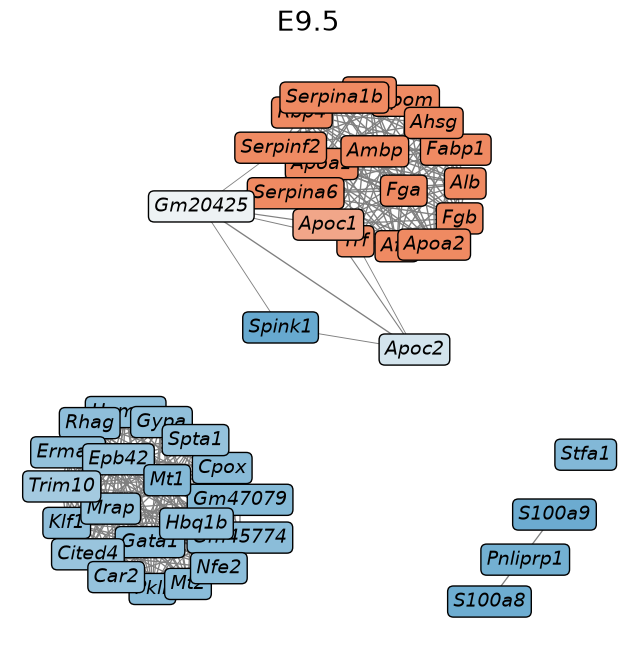

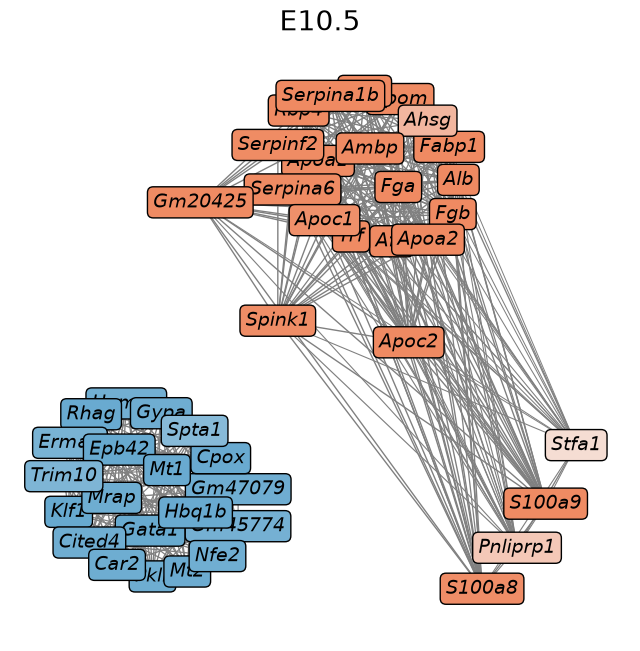

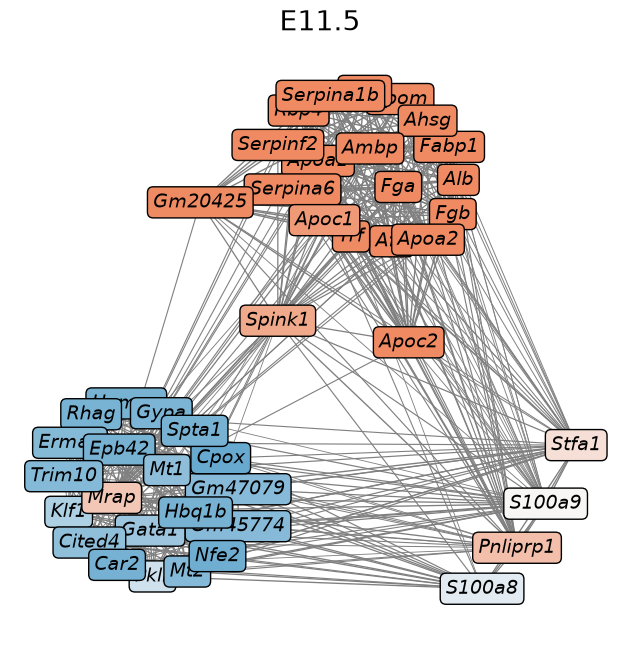

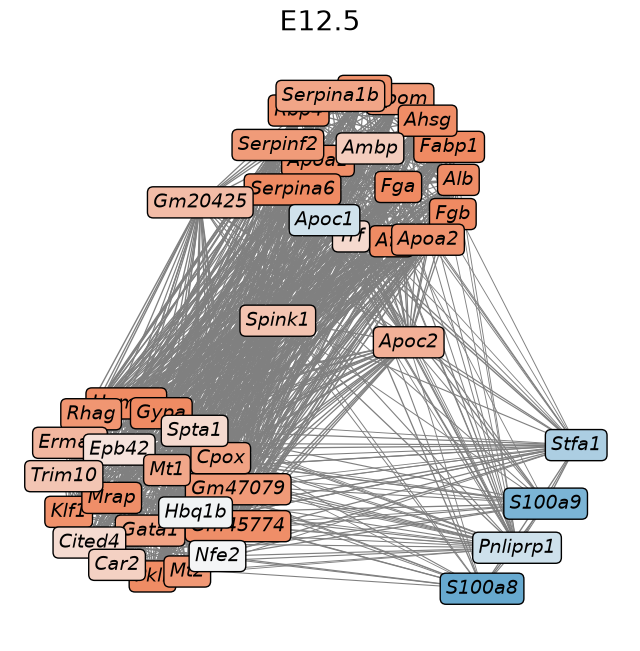

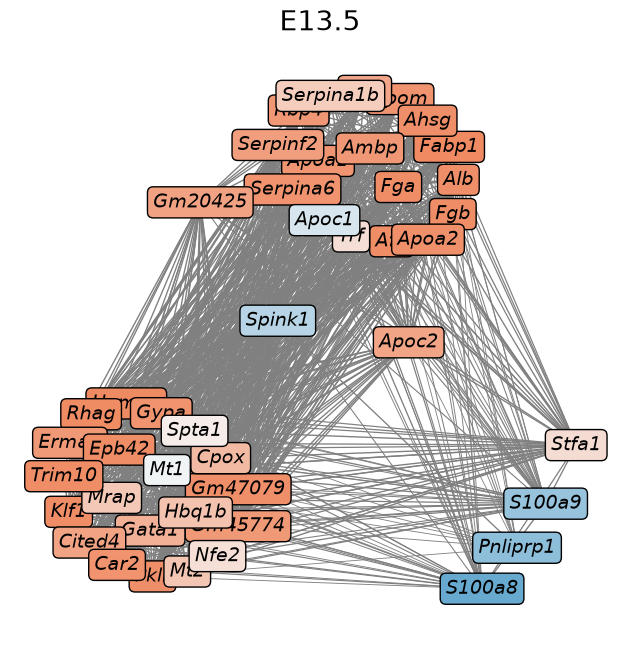

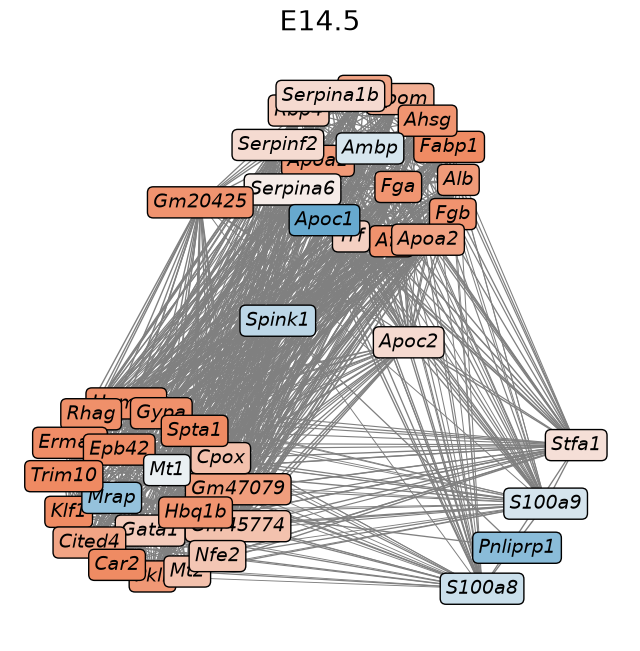

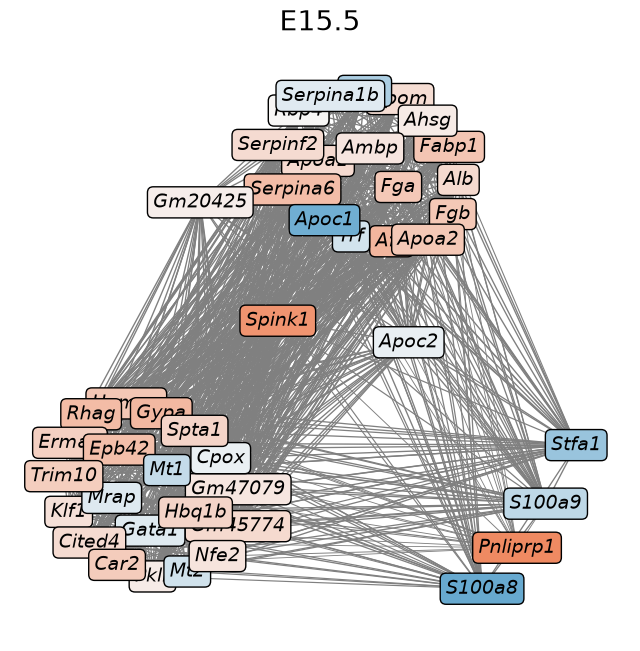

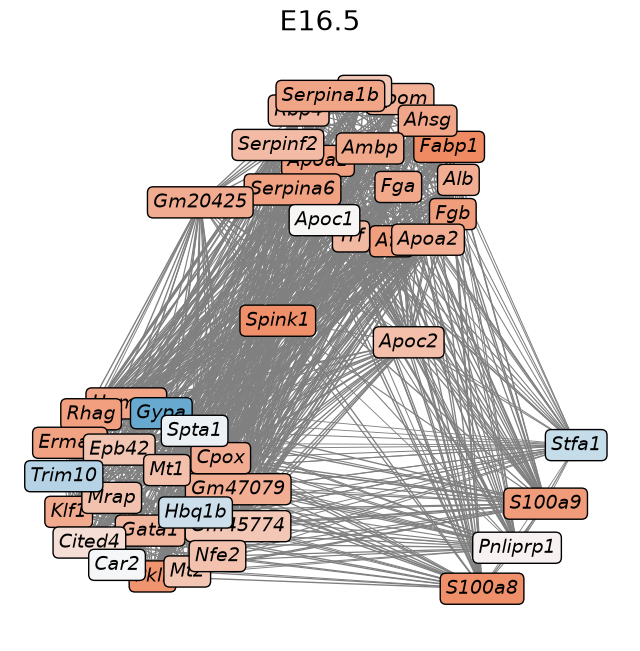

In [15]:
from sklearn.preprocessing import OneHotEncoder
threshold = 0.45
res = query_from_multidatasets(
    query='SpatialLandmark_Liver',
    ftype='Gene', ftype_key='feature_types',
    gdata_list=gdata_dict.values(),
    metric='cosine_similarity',
    metric_threshold=threshold,
    smaller_is_better=False,
)
gene_profiles = list(res.index.tolist())
print(len(gene_profiles))

ggfc = []
scores = []
for time in times:
    gdata = gdata_dict[time].copy()
    ggc = cosine_similarity(gdata[gene_profiles].obsm['feature_embedding'])
    score = cosine_similarity(
        gdata[gene_profiles].obsm['feature_embedding'],
        gdata['SpatialLandmark_Liver'].obsm['feature_embedding']
    ).reshape(-1, )
    ggfc.append(ggc)
    scores.append(score)

ggfc_mean = np.mean(ggfc, axis=0)
layout = None
G = matrix_to_graph(ggfc[0], threshold=0.5)
layout = G.layout("kamada_kawai")
layout.scale(scale=4)

for i, time in enumerate(times):
    fig, ax = plt.subplots(1, 1, figsize=(8, 8))
    # ax = axs[i]
    time_G_ig = matrix_to_graph(ggfc[i], threshold=0.5)
    node_colors = color_by_scores(scores[i])
    if layout is None:
        layout = time_G_ig.layout('kamada_kawai').scale(4)

    G_nx = nx.Graph()
    for v in range(time_G_ig.vcount()):
        G_nx.add_node(v, label=gene_profiles[v])
    for e in time_G_ig.es:
        G_nx.add_edge(e.source, e.target, weight=e["weight"])
    pos = {i: layout[i] for i in range(time_G_ig.vcount())}

    edges = G_nx.edges()
    weights = [G_nx[u][v]['weight'] for u, v in edges]
    nx.draw_networkx_edges(
        G_nx, pos, ax=ax, edge_color='gray',
        width=[(1 + 4*w) / 5 for w in weights]
    )

    labels = nx.get_node_attributes(G_nx, 'label')
    for node, (x, y) in pos.items():
        label = labels[node]
        ax.text(x, y, 
                label, # if i == 0 else ' ' * len(label),
                fontsize=14,
                ha='center', va='center',
                fontdict={'style':'italic'},
                bbox=dict(facecolor=node_colors[node], edgecolor='black', boxstyle='round,pad=0.3'))

    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(str(time), fontsize=20)

    plt.subplots_adjust(wspace=-0.2)
    plt.savefig(OUTPUTS_DIR / 'fig4g{i}.eps', format='eps', dpi=300, bbox_inches='tight')
    plt.show()